# Experiment 2: Covariance, Eigenvalues and Eigenvectors Analysis

A hospital lab records five correlated blood measurements for 200 patients. We simulate measurements from shared latent factors, standardise the features, and use eigendecomposition to identify the strongest directions of variation.

**Tools:** NumPy, Pandas, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Create a 200-row patient table and standardise each feature.  2. Calculate and plot covariance and correlation matrices.  3. Compute and sort eigenvalues/eigenvectors.  4. Plot the first two principal-component scores and feature loading arrows.  5. Report variance explained by each component.

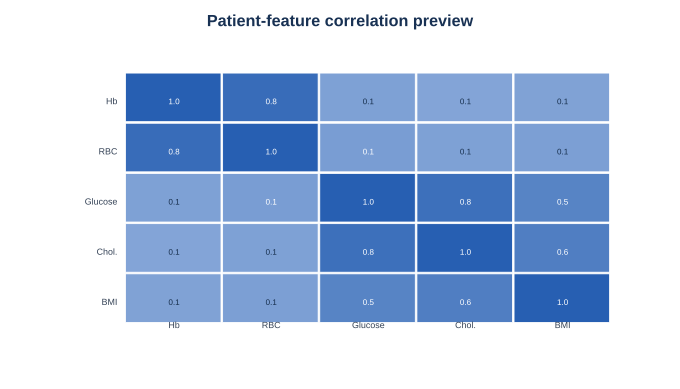

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2)
latent = rng.normal(size=(200, 2))
mix = np.array([[1.0, .2], [.8, .1], [.1, .9], [.2, .8], [.4, .4]])
noise = rng.normal(scale=.35, size=(200, 5))
X = latent @ mix.T + noise
X[:, 0] = 13.5 + 1.2 * X[:, 0]       # haemoglobin
X[:, 1] = 4.8 + .7 * X[:, 1]         # RBC count
X[:, 2] = 95 + 12 * X[:, 2]          # glucose
X[:, 3] = 185 + 30 * X[:, 3]         # cholesterol
X[:, 4] = 25 + 4 * X[:, 4]           # BMI
features = ["haemoglobin", "RBC", "glucose", "cholesterol", "BMI"]
df = pd.DataFrame(X, columns=features)
Z = (df - df.mean()) / df.std(ddof=1)
cov = np.cov(Z, rowvar=False)
corr = np.corrcoef(Z, rowvar=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, matrix, title in zip(axes, [cov, corr], ["Covariance", "Correlation"]):
    im = ax.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(5), features, rotation=45, ha="right")
    ax.set_yticks(range(5), features); ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

values, vectors = np.linalg.eigh(cov)
order = np.argsort(values)[::-1]
values, vectors = values[order], vectors[:, order]
variance_pct = 100 * values / values.sum()
scores = Z.to_numpy() @ vectors
print("Eigenvalues:", np.round(values, 3))
print("Variance explained (%):", np.round(variance_pct, 2))
print("Cumulative (%):", np.round(np.cumsum(variance_pct), 2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(scores[:, 0], scores[:, 1], alpha=.55, s=18)
scale = np.max(np.abs(scores[:, :2])) * .65
for k, name in enumerate(features):
    ax.arrow(0, 0, vectors[k, 0]*scale, vectors[k, 1]*scale,
             color="crimson", head_width=.12, length_includes_head=True)
    ax.text(vectors[k, 0]*scale*1.12, vectors[k, 1]*scale*1.12, name, color="crimson")
ax.set_xlabel("PC1 score"); ax.set_ylabel("PC2 score")
ax.set_title("Patients projected onto the first two principal directions")
ax.grid(alpha=.2); plt.tight_layout(); plt.show()